# Analysis of the HH-LAP-SIPA time-budget experiment

## 1. Imports and configuration

In [1]:
from pathlib import Path
import tarfile
import shutil
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy import stats as scipy_stats
except Exception:
    scipy_stats = None
    warnings.warn("scipy is not available. Statistical tests and t-based CI95 will be skipped or approximated.")

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [2]:
# ============================================================
# USER CONFIGURATION
# ============================================================

BASE_DIR = Path.cwd()

# Put the final archive next to this notebook using this name.
TAR_PATH = BASE_DIR / "time_budget_1000_results.tar.gz"

# Extraction and analysis output folders.
WORK_DIR = BASE_DIR / "time_budget_1000_extracted"
OUTPUT_DIR = BASE_DIR / "time_budget_1000_analysis_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENT_NAME = "time_budget_1000"
EXPECTED_EXECUTIONS = 320
EXPECTED_INSTANCES = 4
EXPECTED_RUNS = 10
EXPECTED_ALGORITHMS = ["hh_lap_v0", "hh_lap_v1"]
EXPECTED_TIME_LIMITS = [300, 600, 900, 1200]

ALGORITHM_LABELS = {
    "hh_lap_v0": "HH-LAP-SIPA-Lite",
    "hh_lap_v1": "HH-LAP-SIPA-Intensive",
}

ALGORITHM_ORDER = ["hh_lap_v0", "hh_lap_v1"]
LABEL_ORDER = [ALGORITHM_LABELS[a] for a in ALGORITHM_ORDER]

TIME_LIMIT_LABELS = {
    300: "5 min",
    600: "10 min",
    900: "15 min",
    1200: "20 min",
}

print("BASE_DIR:", BASE_DIR)
print("TAR_PATH:", TAR_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

BASE_DIR: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\time_budget_comparison
TAR_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\time_budget_comparison\time_budget_1000_results.tar.gz
OUTPUT_DIR: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\time_budget_comparison\time_budget_1000_analysis_outputs


## 2. Extract archive and locate the results directory

The expected final archive contains `results/time_budget_1000/`. The external `nohup` log folder, such as `results/logs_time_budget_1000/`, is not required for this analysis because the main execution log is inside `<RESULTS_DIR>/logs/run_general.log`.

In [3]:
def safe_extract_tar(tar_path: Path, extract_to: Path) -> None:
    """Safely extract a .tar.gz file, avoiding path traversal."""
    extract_to = extract_to.resolve()

    with tarfile.open(tar_path, "r:gz") as tar:
        for member in tar.getmembers():
            target_path = (extract_to / member.name).resolve()
            if not str(target_path).startswith(str(extract_to)):
                raise RuntimeError(f"Unsafe path inside tar: {member.name}")
        tar.extractall(extract_to)


def looks_like_results_dir(path: Path) -> bool:
    return (
        path.is_dir()
        and (path / "statistics").is_dir()
        and (path / "pareto").is_dir()
        and (path / "checkpoints").is_dir()
    )


# If the archive exists, extract it from scratch.
if TAR_PATH.exists():
    if WORK_DIR.exists():
        shutil.rmtree(WORK_DIR)
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    safe_extract_tar(TAR_PATH, WORK_DIR)
    print("Archive extracted to:", WORK_DIR)
else:
    print("Archive not found. The notebook will try to locate an already extracted results directory.")

# Candidate locations after either automatic or manual extraction.
candidates = []

if WORK_DIR.exists():
    candidates.extend([
        WORK_DIR / "results" / EXPERIMENT_NAME,
        WORK_DIR / EXPERIMENT_NAME,
    ])
    candidates.extend(WORK_DIR.glob(f"**/{EXPERIMENT_NAME}"))

candidates.extend([
    BASE_DIR / "results" / EXPERIMENT_NAME,
    BASE_DIR / EXPERIMENT_NAME,
])

# Deduplicate while preserving order.
seen = set()
unique_candidates = []
for c in candidates:
    c = c.resolve()
    if c not in seen:
        seen.add(c)
        unique_candidates.append(c)

ROOT = None
for c in unique_candidates:
    if looks_like_results_dir(c):
        ROOT = c
        break

if ROOT is None:
    print("Candidates checked:")
    for c in unique_candidates:
        print(" -", c)
    raise FileNotFoundError(
        "Could not locate the results directory. Expected something like results/time_budget_1000/."
    )

print("ROOT:", ROOT)
print("Available subdirectories:", sorted([p.name for p in ROOT.iterdir() if p.is_dir()]))

Archive extracted to: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\time_budget_comparison\time_budget_1000_extracted
ROOT: C:\Code\VRAIN-practicas\Code\Teachers+Centers\results\time_budget_comparison\time_budget_1000_extracted\results\time_budget_1000
Available subdirectories: ['assignments', 'checkpoints', 'hypervolume', 'logs', 'pareto', 'statistics']


## 3. Load statistics, Pareto fronts, checkpoints, and logs

In [4]:
STATS_PATH = ROOT / "statistics" / "statistics_all.csv"
PARETO_DIR = ROOT / "pareto"
CHECKPOINTS_DIR = ROOT / "checkpoints"
INTERNAL_LOG_PATH = ROOT / "logs" / "run_general.log"
HYPERVOLUME_DIR = ROOT / "hypervolume"
HV_RUN_PATH = HYPERVOLUME_DIR / "hypervolume_by_run.csv"
HV_SUMMARY_PATH = HYPERVOLUME_DIR / "hypervolume_summary.csv"

required_paths = [STATS_PATH, PARETO_DIR, CHECKPOINTS_DIR]
for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Required path not found: {path}")

stats_all = pd.read_csv(STATS_PATH)
pareto_files = sorted(PARETO_DIR.glob("*.csv"))
checkpoint_files = sorted(CHECKPOINTS_DIR.glob("*.done"))

print("statistics_all:", stats_all.shape)
print("Pareto files:", len(pareto_files))
print("Checkpoint files:", len(checkpoint_files))
print("Internal log exists:", INTERNAL_LOG_PATH.exists())

if INTERNAL_LOG_PATH.exists():
    print("\nLast internal log lines:")
    with open(INTERNAL_LOG_PATH, "r", encoding="utf-8", errors="replace") as f:
        lines = f.readlines()
    for line in lines[-10:]:
        print(line.rstrip())

display(stats_all.head())

statistics_all: (320, 20)
Pareto files: 320
Checkpoint files: 320
Internal log exists: True

Last internal log lines:
[2026-07-11 18:36:32] [316/320] hh_lap_v1 | problem_instance_ext_1000_3.txt | run 05 | 1200s | OK | elapsed=1200.90s | pareto_size=101
[2026-07-11 18:36:32] [317/320] hh_lap_v1 | problem_instance_ext_1000_3.txt | run 06 | 1200s | START | seed=630546420
[2026-07-11 18:56:33] [317/320] hh_lap_v1 | problem_instance_ext_1000_3.txt | run 06 | 1200s | OK | elapsed=1201.21s | pareto_size=101
[2026-07-11 18:56:33] [318/320] hh_lap_v1 | problem_instance_ext_1000_3.txt | run 07 | 1200s | START | seed=630546421
[2026-07-11 19:16:37] [318/320] hh_lap_v1 | problem_instance_ext_1000_3.txt | run 07 | 1200s | OK | elapsed=1203.58s | pareto_size=103
[2026-07-11 19:16:37] [319/320] hh_lap_v1 | problem_instance_ext_1000_3.txt | run 08 | 1200s | START | seed=630546422
[2026-07-11 19:36:41] [319/320] hh_lap_v1 | problem_instance_ext_1000_3.txt | run 08 | 1200s | OK | elapsed=1203.87s | pare

,timestamp,algorithm,instance,n_students,run_id,seed,time_limit_seconds,elapsed_seconds,status,error_message,pareto_size,generated,feasible,failures,inserted_into_pareto,iterations,generations,population_size,offspring_size,reference_points
0,2026-07-09 00:55:59,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,0,18195331,300,300.104056,ok,NaN,14,NaN,NaN,NaN,37,39,NaN,NaN,NaN,NaN
1,2026-07-09 01:01:00,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,1,18195332,300,300.223796,ok,NaN,14,NaN,NaN,NaN,35,39,NaN,NaN,NaN,NaN
2,2026-07-09 01:06:01,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,2,18195333,300,301.382905,ok,NaN,12,NaN,NaN,NaN,33,39,NaN,NaN,NaN,NaN
3,2026-07-09 01:11:08,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,3,18195334,300,306.365015,ok,NaN,13,NaN,NaN,NaN,35,40,NaN,NaN,NaN,NaN
4,2026-07-09 01:16:09,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,4,18195335,300,300.278893,ok,NaN,13,NaN,NaN,NaN,33,39,NaN,NaN,NaN,NaN


## 4. Metadata normalization and integrity checks

In [5]:
def normalize_instance_name(x):
    """Normalize an instance filename/path to a stable name without extension."""
    name = Path(str(x)).name
    name = name.replace(".txt", "")
    name = name.replace(".csv", "")
    return name


def extract_n_students_from_instance(instance_name):
    """Extract n_students from names such as problem_instance_ext_1000_3."""
    match = re.search(r"_(\d+)_(\d+)$", str(instance_name))
    if match:
        return int(match.group(1))
    return np.nan


def extract_time_limit_from_name(name):
    match = re.search(r"__t(\d+)s__", str(name))
    if match:
        return int(match.group(1))
    return np.nan


def extract_run_id_from_name(name):
    match = re.search(r"__run_(\d+)", str(name))
    if match:
        return int(match.group(1))
    match = re.search(r"run_(\d+)", str(name))
    if match:
        return int(match.group(1))
    return np.nan


def normalize_time_limit_column(df):
    """Return a copy of df with a standard time_limit_seconds column when possible."""
    df = df.copy()
    possible = [
        "time_limit_seconds",
        "time_limit",
        "filename_time_limit_seconds",
        "time_budget_seconds",
    ]
    found = None
    for col in possible:
        if col in df.columns:
            found = col
            break
    if found is not None:
        df["time_limit_seconds"] = pd.to_numeric(df[found], errors="coerce").astype("Int64")
    return df


def add_common_metadata(df):
    df = df.copy()
    if "instance" in df.columns:
        df["instance_clean"] = df["instance"].apply(normalize_instance_name)
    elif "instance_clean" not in df.columns:
        raise ValueError("No instance or instance_clean column found.")

    if "n_students" not in df.columns:
        df["n_students"] = df["instance_clean"].apply(extract_n_students_from_instance)

    if "algorithm_label" not in df.columns and "algorithm" in df.columns:
        df["algorithm_label"] = df["algorithm"].map(ALGORITHM_LABELS)

    if "algorithm" in df.columns:
        df["algorithm"] = pd.Categorical(df["algorithm"], categories=ALGORITHM_ORDER, ordered=True)

    df = normalize_time_limit_column(df)
    return df


stats_all = add_common_metadata(stats_all)

# If time_limit_seconds is missing in statistics, try to recover it from an output filename column.
if "time_limit_seconds" not in stats_all.columns or stats_all["time_limit_seconds"].isna().all():
    filename_candidates = [c for c in stats_all.columns if "file" in c.lower() or "path" in c.lower()]
    for col in filename_candidates:
        parsed = stats_all[col].apply(extract_time_limit_from_name)
        if parsed.notna().any():
            stats_all["time_limit_seconds"] = parsed.astype("Int64")
            print(f"Recovered time_limit_seconds from column {col}")
            break

if "time_limit_seconds" in stats_all.columns:
    stats_all["time_limit_label"] = stats_all["time_limit_seconds"].map(TIME_LIMIT_LABELS)

print("Statistics columns:")
print(list(stats_all.columns))

display(stats_all.head())

Statistics columns:
['timestamp', 'algorithm', 'instance', 'n_students', 'run_id', 'seed', 'time_limit_seconds', 'elapsed_seconds', 'status', 'error_message', 'pareto_size', 'generated', 'feasible', 'failures', 'inserted_into_pareto', 'iterations', 'generations', 'population_size', 'offspring_size', 'reference_points', 'instance_clean', 'algorithm_label', 'time_limit_label']


,timestamp,algorithm,instance,n_students,run_id,seed,time_limit_seconds,elapsed_seconds,status,error_message,pareto_size,generated,feasible,failures,inserted_into_pareto,iterations,generations,population_size,offspring_size,reference_points,instance_clean,algorithm_label,time_limit_label
0,2026-07-09 00:55:59,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,0,18195331,300,300.104056,ok,NaN,14,NaN,NaN,NaN,37,39,NaN,NaN,NaN,NaN,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,5 min
1,2026-07-09 01:01:00,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,1,18195332,300,300.223796,ok,NaN,14,NaN,NaN,NaN,35,39,NaN,NaN,NaN,NaN,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,5 min
2,2026-07-09 01:06:01,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,2,18195333,300,301.382905,ok,NaN,12,NaN,NaN,NaN,33,39,NaN,NaN,NaN,NaN,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,5 min
3,2026-07-09 01:11:08,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,3,18195334,300,306.365015,ok,NaN,13,NaN,NaN,NaN,35,40,NaN,NaN,NaN,NaN,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,5 min
4,2026-07-09 01:16:09,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,4,18195335,300,300.278893,ok,NaN,13,NaN,NaN,NaN,33,39,NaN,NaN,NaN,NaN,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,5 min


In [6]:
# ============================================================
# INTEGRITY CHECKS
# ============================================================

summary_checks = {
    "statistics_rows": len(stats_all),
    "pareto_files": len(pareto_files),
    "checkpoint_files": len(checkpoint_files),
    "algorithms": sorted([str(x) for x in stats_all["algorithm"].dropna().unique()]) if "algorithm" in stats_all.columns else None,
    "instances": stats_all["instance_clean"].nunique() if "instance_clean" in stats_all.columns else None,
    "runs": sorted(stats_all["run_id"].dropna().unique().tolist()) if "run_id" in stats_all.columns else None,
    "time_limits": sorted(stats_all["time_limit_seconds"].dropna().astype(int).unique().tolist()) if "time_limit_seconds" in stats_all.columns else None,
}

summary_checks_df = pd.DataFrame([summary_checks])
display(summary_checks_df)
summary_checks_df.to_csv(OUTPUT_DIR / "00_integrity_summary.csv", index=False)

print("Expected executions:", EXPECTED_EXECUTIONS)
print("Actual statistics rows:", len(stats_all))
print("Actual Pareto files:", len(pareto_files))
print("Actual checkpoint files:", len(checkpoint_files))

if len(stats_all) != EXPECTED_EXECUTIONS:
    print("WARNING: statistics rows do not match the expected value.")
if len(pareto_files) != EXPECTED_EXECUTIONS:
    print("WARNING: Pareto files do not match the expected value.")
if len(checkpoint_files) != EXPECTED_EXECUTIONS:
    print("WARNING: checkpoint files do not match the expected value.")

if "status" in stats_all.columns:
    print("\nExecution status counts:")
    display(stats_all["status"].value_counts(dropna=False).rename_axis("status").reset_index(name="count"))

if "time_limit_seconds" in stats_all.columns:
    print("\nExecutions by algorithm and time limit:")
    display(pd.crosstab(stats_all["algorithm_label"], stats_all["time_limit_seconds"]))

,statistics_rows,pareto_files,checkpoint_files,algorithms,instances,runs,time_limits
0,320,320,320,"[hh_lap_v0, hh_lap_v1]",4,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]","[300, 600, 900, 1200]"


Expected executions: 320
Actual statistics rows: 320
Actual Pareto files: 320
Actual checkpoint files: 320

Execution status counts:


,status,count
0,ok,320



Executions by algorithm and time limit:


time_limit_seconds,300,600,900,1200
algorithm_label,,,,
HH-LAP-SIPA-Intensive,40,40,40,40
HH-LAP-SIPA-Lite,40,40,40,40


## 5. Read Pareto files

The time limit is recovered from filenames such as `__t300s__run_00.csv`. This is important because several executions share the same algorithm, instance, and run id but differ in time budget.

In [7]:
required_objective_cols = ["tau_sum", "eta_sum", "lbar_sum", "sigma_sum"]

pareto_dfs = []

for file in pareto_files:
    df = pd.read_csv(file)
    missing_cols = [c for c in required_objective_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing columns {missing_cols} in {file.name}")

    df["source_file"] = file.name
    df["source_path"] = str(file)

    # Recover metadata from file when not present.
    if "time_limit_seconds" not in df.columns or pd.to_numeric(df.get("time_limit_seconds"), errors="coerce").isna().all():
        df["time_limit_seconds"] = extract_time_limit_from_name(file.name)

    if "run_id" not in df.columns or pd.to_numeric(df.get("run_id"), errors="coerce").isna().all():
        df["run_id"] = extract_run_id_from_name(file.name)

    pareto_dfs.append(df)

pareto_all = pd.concat(pareto_dfs, ignore_index=True)
pareto_all = add_common_metadata(pareto_all)
pareto_all["time_limit_seconds"] = pd.to_numeric(pareto_all["time_limit_seconds"], errors="coerce").astype("Int64")
pareto_all["time_limit_label"] = pareto_all["time_limit_seconds"].map(TIME_LIMIT_LABELS)

# Objective values normalized by number of students for interpretability.
pareto_all["tau_per_student"] = pareto_all["tau_sum"] / pareto_all["n_students"]
pareto_all["eta_per_student"] = pareto_all["eta_sum"] / pareto_all["n_students"]

print("All Pareto solutions:", pareto_all.shape)
display(pareto_all.head())

pareto_all.to_csv(OUTPUT_DIR / "01_all_pareto_solutions.csv", index=False)

All Pareto solutions: (16117, 21)


,timestamp,algorithm,instance,n_students,run_id,solution_id,seed,iteration,objective_value,tau_sum,eta_sum,lbar_sum,sigma_sum,source_file,source_path,time_limit_seconds,instance_clean,algorithm_label,time_limit_label,tau_per_student,eta_per_student
0,2026-07-09 06:13:14,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,0,0,18195331,2,393.495995,773.923013,351.4393,1.608096,0.591954,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,C:\Code\VRAIN-practicas\Code\Teachers+Centers\...,1200,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,20 min,0.773923,0.351439
1,2026-07-09 06:13:14,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,0,1,18195331,2,338.487900,392.398027,575.7983,1.608096,0.591954,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,C:\Code\VRAIN-practicas\Code\Teachers+Centers\...,1200,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,20 min,0.392398,0.575798
2,2026-07-09 06:13:14,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,0,2,18195331,16,402.298799,787.774973,362.6077,1.621397,0.108571,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,C:\Code\VRAIN-practicas\Code\Teachers+Centers\...,1200,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,20 min,0.787775,0.362608
3,2026-07-09 06:13:14,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,0,3,18195331,16,347.649732,402.337283,591.9052,1.621397,0.108571,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,C:\Code\VRAIN-practicas\Code\Teachers+Centers\...,1200,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,20 min,0.402337,0.591905
4,2026-07-09 06:13:14,hh_lap_v0,problem_instance_ext_1000_0.txt,1000,0,4,18195331,28,403.148702,787.404953,365.4952,1.629097,0.405325,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,C:\Code\VRAIN-practicas\Code\Teachers+Centers\...,1200,problem_instance_ext_1000_0,HH-LAP-SIPA-Lite,20 min,0.787405,0.365495


In [8]:
# Check Pareto files per algorithm/time limit.
pareto_file_metadata = []
for file in pareto_files:
    parts = file.stem.split("__")
    algorithm = parts[0] if len(parts) > 0 else None
    instance = parts[1] if len(parts) > 1 else None
    pareto_file_metadata.append({
        "file": file.name,
        "algorithm": algorithm,
        "algorithm_label": ALGORITHM_LABELS.get(algorithm, algorithm),
        "instance_clean": normalize_instance_name(instance),
        "n_students": extract_n_students_from_instance(normalize_instance_name(instance)),
        "time_limit_seconds": extract_time_limit_from_name(file.name),
        "run_id": extract_run_id_from_name(file.name),
    })

pareto_file_metadata = pd.DataFrame(pareto_file_metadata)
display(pareto_file_metadata.head())

pareto_file_counts = (
    pareto_file_metadata
    .groupby(["algorithm_label", "time_limit_seconds"])
    .size()
    .reset_index(name="n_files")
    .sort_values(["time_limit_seconds", "algorithm_label"])
)

display(pareto_file_counts)
pareto_file_metadata.to_csv(OUTPUT_DIR / "01_pareto_file_metadata.csv", index=False)
pareto_file_counts.to_csv(OUTPUT_DIR / "01_pareto_file_counts.csv", index=False)

,file,algorithm,algorithm_label,instance_clean,n_students,time_limit_seconds,run_id
0,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1200,0
1,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1200,1
2,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1200,2
3,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1200,3
4,hh_lap_v0__problem_instance_ext_1000_0__t1200s...,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1200,4


,algorithm_label,time_limit_seconds,n_files
0,HH-LAP-SIPA-Intensive,300,40
4,HH-LAP-SIPA-Lite,300,40
1,HH-LAP-SIPA-Intensive,600,40
5,HH-LAP-SIPA-Lite,600,40
2,HH-LAP-SIPA-Intensive,900,40
6,HH-LAP-SIPA-Lite,900,40
3,HH-LAP-SIPA-Intensive,1200,40
7,HH-LAP-SIPA-Lite,1200,40


## 6. Hypervolume computation

This notebook recomputes a normalized hypervolume directly from the Pareto CSV files. This avoids depending on whether `run_hypervolume.py` has already been updated to distinguish `time_limit_seconds`.

For each instance, objective bounds are computed using all Pareto points from both algorithms and all time limits. This makes all time budgets comparable within the same instance.

Objective directions:

```text
tau_sum   -> maximize
eta_sum   -> maximize
lbar_sum  -> minimize
sigma_sum -> minimize
```

For hypervolume, the objectives are transformed into normalized maximization values in `[0, 1]`, using reference point `(0, 0, 0, 0)`.

In [9]:
def nondominated_max(points: np.ndarray) -> np.ndarray:
    """Return non-dominated points for a maximization problem."""
    points = np.asarray(points, dtype=float)
    if len(points) == 0:
        return points

    # Remove duplicate rows first.
    points = np.unique(points, axis=0)
    keep = np.ones(len(points), dtype=bool)

    for i, p in enumerate(points):
        if not keep[i]:
            continue
        # p is dominated if another q is >= p in all dimensions and > p in at least one.
        dominates_p = np.all(points >= p, axis=1) & np.any(points > p, axis=1)
        if np.any(dominates_p):
            keep[i] = False

    return points[keep]


def hypervolume_origin_max(points: np.ndarray) -> float:
    """
    Exact hypervolume of the union of boxes [0, p] for maximization points p in [0, 1]^d.
    Uses a recursive slicing algorithm. Suitable for the small/medium Pareto fronts produced here.
    """
    points = np.asarray(points, dtype=float)

    if points.size == 0:
        return 0.0

    points = points[np.all(np.isfinite(points), axis=1)]
    points = np.clip(points, 0.0, 1.0)
    points = points[np.any(points > 0, axis=1)]

    if len(points) == 0:
        return 0.0

    points = nondominated_max(points)
    d = points.shape[1]

    if d == 1:
        return float(np.max(points[:, 0]))

    levels = np.unique(points[:, -1])
    levels.sort()

    volume = 0.0
    previous = 0.0

    for level in levels:
        width = level - previous
        if width > 0:
            active = points[points[:, -1] >= level, :-1]
            volume += width * hypervolume_origin_max(active)
        previous = level

    return float(volume)


def normalize_objectives_for_instance(df: pd.DataFrame, bounds: dict) -> pd.DataFrame:
    """Transform raw objectives to maximization values in [0, 1]."""
    out = df.copy()

    def norm_max(series, low, high):
        if pd.isna(low) or pd.isna(high) or high == low:
            return pd.Series(np.ones(len(series)), index=series.index)
        return (series - low) / (high - low)

    def norm_min(series, low, high):
        if pd.isna(low) or pd.isna(high) or high == low:
            return pd.Series(np.ones(len(series)), index=series.index)
        return (high - series) / (high - low)

    out["tau_norm"] = norm_max(out["tau_sum"], bounds["min_tau"], bounds["max_tau"])
    out["eta_norm"] = norm_max(out["eta_sum"], bounds["min_eta"], bounds["max_eta"])
    out["lbar_norm"] = norm_min(out["lbar_sum"], bounds["min_lbar"], bounds["max_lbar"])
    out["sigma_norm"] = norm_min(out["sigma_sum"], bounds["min_sigma"], bounds["max_sigma"])

    for col in ["tau_norm", "eta_norm", "lbar_norm", "sigma_norm"]:
        out[col] = out[col].clip(0.0, 1.0)

    return out

In [10]:
# ============================================================
# INSTANCE-SPECIFIC NORMALIZATION BOUNDS
# ============================================================

bounds_rows = []

for instance_clean, group in pareto_all.groupby("instance_clean", observed=True):
    bounds_rows.append({
        "instance_clean": instance_clean,
        "n_students": group["n_students"].iloc[0],
        "min_tau": group["tau_sum"].min(),
        "max_tau": group["tau_sum"].max(),
        "min_eta": group["eta_sum"].min(),
        "max_eta": group["eta_sum"].max(),
        "min_lbar": group["lbar_sum"].min(),
        "max_lbar": group["lbar_sum"].max(),
        "min_sigma": group["sigma_sum"].min(),
        "max_sigma": group["sigma_sum"].max(),
    })

hv_bounds = pd.DataFrame(bounds_rows).sort_values(["n_students", "instance_clean"])
display(hv_bounds)
hv_bounds.to_csv(OUTPUT_DIR / "02_hypervolume_normalization_bounds.csv", index=False)

,instance_clean,n_students,min_tau,max_tau,min_eta,max_eta,min_lbar,max_lbar,min_sigma,max_sigma
0,problem_instance_ext_1000_0,1000,392.398027,788.509433,351.4393,592.1510,1.608096,2.388879,0.001840,0.591954
1,problem_instance_ext_1000_1,1000,389.569016,793.436486,335.6883,588.2792,0.747752,1.012752,0.000523,0.341297
2,problem_instance_ext_1000_2,1000,390.679192,797.444598,348.5029,603.8640,1.281877,2.038324,0.000000,0.471405
3,problem_instance_ext_1000_3,1000,388.098317,800.346238,338.2789,582.7188,1.217533,1.524510,0.000911,0.429185


In [11]:
# ============================================================
# HYPERVOLUME BY RUN / ALGORITHM / INSTANCE / TIME LIMIT
# ============================================================

hv_rows = []
normalized_parts = []

for instance_clean, instance_group in pareto_all.groupby("instance_clean", observed=True):
    bounds = hv_bounds[hv_bounds["instance_clean"] == instance_clean].iloc[0].to_dict()
    instance_norm = normalize_objectives_for_instance(instance_group, bounds)
    normalized_parts.append(instance_norm)

    group_cols = [
        "algorithm",
        "algorithm_label",
        "instance_clean",
        "n_students",
        "run_id",
        "time_limit_seconds",
        "time_limit_label",
    ]

    for keys, run_group in instance_norm.groupby(group_cols, observed=True, dropna=False):
        points = run_group[["tau_norm", "eta_norm", "lbar_norm", "sigma_norm"]].to_numpy(dtype=float)
        hv = hypervolume_origin_max(points)

        row = dict(zip(group_cols, keys))
        row.update({
            "pareto_points": len(run_group),
            "hypervolume": hv,
        })
        hv_rows.append(row)

pareto_all_normalized = pd.concat(normalized_parts, ignore_index=True)
hv_run = pd.DataFrame(hv_rows)

hv_run["time_limit_seconds"] = pd.to_numeric(hv_run["time_limit_seconds"], errors="coerce").astype("Int64")
hv_run = hv_run.sort_values(["time_limit_seconds", "algorithm", "instance_clean", "run_id"]).reset_index(drop=True)

print("hv_run:", hv_run.shape)
display(hv_run.head())

pareto_all_normalized.to_csv(OUTPUT_DIR / "02_all_pareto_solutions_normalized.csv", index=False)
hv_run.to_csv(OUTPUT_DIR / "02_hypervolume_by_run_recomputed.csv", index=False)

hv_run: (320, 9)


,algorithm,algorithm_label,instance_clean,n_students,run_id,time_limit_seconds,time_limit_label,pareto_points,hypervolume
0,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,0,300,5 min,14,0.062995
1,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1,300,5 min,14,0.062995
2,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,2,300,5 min,12,0.062995
3,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,3,300,5 min,13,0.062995
4,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,4,300,5 min,13,0.062995


In [12]:
def ci95(series):
    x = pd.Series(series).dropna().astype(float)
    n = len(x)
    if n <= 1:
        return np.nan
    sem = x.std(ddof=1) / math.sqrt(n)
    if scipy_stats is not None:
        return float(scipy_stats.t.ppf(0.975, df=n - 1) * sem)
    return float(1.96 * sem)


hv_summary = (
    hv_run
    .groupby(["algorithm", "algorithm_label", "instance_clean", "n_students", "time_limit_seconds", "time_limit_label"], observed=True)
    .agg(
        n_runs=("hypervolume", "count"),
        mean_hv=("hypervolume", "mean"),
        std_hv=("hypervolume", "std"),
        median_hv=("hypervolume", "median"),
        min_hv=("hypervolume", "min"),
        max_hv=("hypervolume", "max"),
        ci95_hv=("hypervolume", ci95),
        mean_pareto_points=("pareto_points", "mean"),
    )
    .reset_index()
    .sort_values(["time_limit_seconds", "instance_clean", "algorithm"])
)

display(hv_summary.head())
hv_summary.to_csv(OUTPUT_DIR / "02_hypervolume_summary_recomputed.csv", index=False)

,algorithm,algorithm_label,instance_clean,n_students,time_limit_seconds,time_limit_label,n_runs,mean_hv,std_hv,median_hv,min_hv,max_hv,ci95_hv,mean_pareto_points
0,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,300,5 min,10,0.062996,0.000002,0.062995,0.062995,0.062999,0.000001,13.7
16,hh_lap_v1,HH-LAP-SIPA-Intensive,problem_instance_ext_1000_0,1000,300,5 min,10,0.011632,0.000048,0.011602,0.011602,0.011702,0.000035,74.7
4,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_1,1000,300,5 min,10,0.001687,0.000334,0.001841,0.000904,0.001841,0.000239,4.8
20,hh_lap_v1,HH-LAP-SIPA-Intensive,problem_instance_ext_1000_1,1000,300,5 min,10,0.018615,0.000247,0.018443,0.018440,0.019031,0.000177,74.3
8,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_2,1000,300,5 min,10,0.081477,0.000431,0.081477,0.081066,0.081885,0.000308,15.2


## 7. Global hypervolume comparison by time budget

In [13]:
# Summary at algorithm-time level using all instance-run observations.
hv_by_time_algorithm = (
    hv_run
    .groupby(["time_limit_seconds", "time_limit_label", "algorithm", "algorithm_label"], observed=True)
    .agg(
        n_observations=("hypervolume", "count"),
        mean_hv=("hypervolume", "mean"),
        std_hv=("hypervolume", "std"),
        median_hv=("hypervolume", "median"),
        min_hv=("hypervolume", "min"),
        max_hv=("hypervolume", "max"),
        ci95_hv=("hypervolume", ci95),
        mean_pareto_points=("pareto_points", "mean"),
    )
    .reset_index()
    .sort_values(["time_limit_seconds", "algorithm"])
)

hv_by_time_algorithm["ci95_low"] = hv_by_time_algorithm["mean_hv"] - hv_by_time_algorithm["ci95_hv"]
hv_by_time_algorithm["ci95_high"] = hv_by_time_algorithm["mean_hv"] + hv_by_time_algorithm["ci95_hv"]

display(hv_by_time_algorithm)
hv_by_time_algorithm.to_csv(OUTPUT_DIR / "03_hv_by_time_algorithm.csv", index=False)

,time_limit_seconds,time_limit_label,algorithm,algorithm_label,n_observations,mean_hv,std_hv,median_hv,min_hv,max_hv,ci95_hv,mean_pareto_points,ci95_low,ci95_high
0,300,5 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.038670,0.034720,0.035922,0.000904,0.081885,0.011104,12.750,0.027566,0.049774
1,300,5 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.018445,0.008123,0.015247,0.011602,0.031484,0.002598,59.375,0.015848,0.021043
2,600,10 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.038845,0.034722,0.035987,0.001295,0.082017,0.011104,15.775,0.027740,0.049949
3,600,10 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.021168,0.008758,0.018920,0.012940,0.034032,0.002801,73.575,0.018367,0.023969
4,900,15 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.038969,0.034727,0.036186,0.001470,0.082033,0.011106,18.350,0.027863,0.050076
5,900,15 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.022459,0.008178,0.020773,0.013933,0.034040,0.002616,93.175,0.019843,0.025074
6,1200,20 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.039088,0.034846,0.036223,0.001480,0.082161,0.011144,20.200,0.027944,0.050233
7,1200,20 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.023121,0.008562,0.021793,0.013956,0.034795,0.002738,109.725,0.020383,0.025860


In [14]:
# Pivot table: rows = time limits, columns = algorithms.
hv_by_time_pivot = hv_by_time_algorithm.pivot_table(
    index=["time_limit_seconds", "time_limit_label"],
    columns="algorithm_label",
    values="mean_hv",
    observed=True,
)

hv_by_time_pivot = hv_by_time_pivot[LABEL_ORDER]
display(hv_by_time_pivot)
hv_by_time_pivot.to_csv(OUTPUT_DIR / "03_hv_by_time_pivot.csv")

,algorithm_label,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive
time_limit_seconds,time_limit_label,,
300,5 min,0.038670,0.018445
600,10 min,0.038845,0.021168
900,15 min,0.038969,0.022459
1200,20 min,0.039088,0.023121


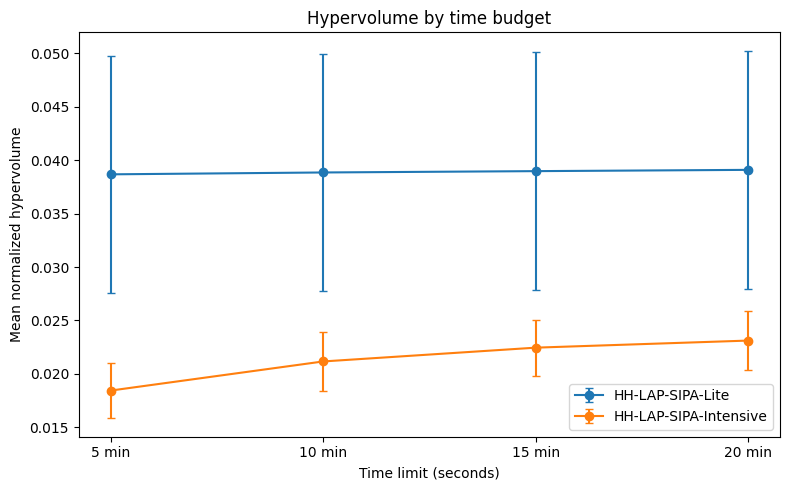

In [15]:
# Figure: mean HV by time limit.
plt.figure(figsize=(8, 5))

for algorithm in ALGORITHM_ORDER:
    sub = hv_by_time_algorithm[hv_by_time_algorithm["algorithm"] == algorithm].sort_values("time_limit_seconds")
    plt.errorbar(
        sub["time_limit_seconds"],
        sub["mean_hv"],
        yerr=sub["ci95_hv"],
        marker="o",
        capsize=3,
        label=ALGORITHM_LABELS[algorithm],
    )

plt.xlabel("Time limit (seconds)")
plt.ylabel("Mean normalized hypervolume")
plt.title("Hypervolume by time budget")
plt.xticks(EXPECTED_TIME_LIMITS, [TIME_LIMIT_LABELS[t] for t in EXPECTED_TIME_LIMITS])
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_fig_hv_by_time_algorithm.png", dpi=300)
plt.show()

## 8. Lite vs Intensive paired comparison

The most direct comparison is paired by:

```text
instance_clean + run_id + time_limit_seconds
```

For each pair, the notebook computes:

```text
HV difference = Lite HV - Intensive HV
```

Positive values favor Lite. Negative values favor Intensive.

In [16]:
LITE_LABEL = ALGORITHM_LABELS["hh_lap_v0"]
INTENSIVE_LABEL = ALGORITHM_LABELS["hh_lap_v1"]

hv_pair_pivot = hv_run.pivot_table(
    index=["instance_clean", "n_students", "run_id", "time_limit_seconds", "time_limit_label"],
    columns="algorithm_label",
    values="hypervolume",
    observed=True,
)

hv_pair_pivot = hv_pair_pivot[LABEL_ORDER].reset_index()
hv_pair_pivot["diff_lite_minus_intensive"] = hv_pair_pivot[LITE_LABEL] - hv_pair_pivot[INTENSIVE_LABEL]
hv_pair_pivot["winner"] = np.where(
    hv_pair_pivot["diff_lite_minus_intensive"] >= 0,
    LITE_LABEL,
    INTENSIVE_LABEL,
)

hv_pair_pivot = hv_pair_pivot.sort_values(["time_limit_seconds", "instance_clean", "run_id"])
display(hv_pair_pivot.head())
hv_pair_pivot.to_csv(OUTPUT_DIR / "04_lite_vs_intensive_paired_hv_by_run.csv", index=False)

algorithm_label,instance_clean,n_students,run_id,time_limit_seconds,time_limit_label,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive,diff_lite_minus_intensive,winner
0,problem_instance_ext_1000_0,1000,0,300,5 min,0.062995,0.011702,0.051293,HH-LAP-SIPA-Lite
4,problem_instance_ext_1000_0,1000,1,300,5 min,0.062995,0.011702,0.051293,HH-LAP-SIPA-Lite
8,problem_instance_ext_1000_0,1000,2,300,5 min,0.062995,0.011702,0.051293,HH-LAP-SIPA-Lite
12,problem_instance_ext_1000_0,1000,3,300,5 min,0.062995,0.011602,0.051394,HH-LAP-SIPA-Lite
16,problem_instance_ext_1000_0,1000,4,300,5 min,0.062995,0.011602,0.051394,HH-LAP-SIPA-Lite


In [17]:
def wilcoxon_test(values):
    values = pd.Series(values).dropna().astype(float)
    values = values[values != 0]

    if len(values) == 0 or scipy_stats is None:
        return pd.Series({"wilcoxon_statistic": np.nan, "p_value": np.nan, "n_nonzero_pairs": len(values)})

    stat, p_value = scipy_stats.wilcoxon(values, alternative="two-sided", zero_method="wilcox")
    return pd.Series({"wilcoxon_statistic": stat, "p_value": p_value, "n_nonzero_pairs": len(values)})


paired_hv_summary = (
    hv_pair_pivot
    .groupby(["time_limit_seconds", "time_limit_label"], observed=True)
    .agg(
        n_pairs=("diff_lite_minus_intensive", "count"),
        mean_diff_lite_minus_intensive=("diff_lite_minus_intensive", "mean"),
        std_diff_lite_minus_intensive=("diff_lite_minus_intensive", "std"),
        median_diff_lite_minus_intensive=("diff_lite_minus_intensive", "median"),
        ci95_diff=("diff_lite_minus_intensive", ci95),
        lite_wins=("winner", lambda s: (s == LITE_LABEL).sum()),
        intensive_wins=("winner", lambda s: (s == INTENSIVE_LABEL).sum()),
    )
    .reset_index()
)

wilcoxon_by_time = (
    hv_pair_pivot
    .groupby(["time_limit_seconds", "time_limit_label"], observed=True)["diff_lite_minus_intensive"]
    .apply(wilcoxon_test)
    .reset_index()
)

# If groupby/apply returned a long format, reshape it.
if "level_2" in wilcoxon_by_time.columns:
    wilcoxon_by_time = wilcoxon_by_time.pivot_table(
        index=["time_limit_seconds", "time_limit_label"],
        columns="level_2",
        values="diff_lite_minus_intensive",
        observed=True,
    ).reset_index()

paired_hv_summary = paired_hv_summary.merge(
    wilcoxon_by_time,
    on=["time_limit_seconds", "time_limit_label"],
    how="left",
)

paired_hv_summary = paired_hv_summary.sort_values("time_limit_seconds")
display(paired_hv_summary)
paired_hv_summary.to_csv(OUTPUT_DIR / "04_lite_vs_intensive_hv_summary_by_time.csv", index=False)

,time_limit_seconds,time_limit_label,n_pairs,mean_diff_lite_minus_intensive,std_diff_lite_minus_intensive,median_diff_lite_minus_intensive,ci95_diff,lite_wins,intensive_wins,n_nonzero_pairs,p_value,wilcoxon_statistic
0,300,5 min,40,0.020225,0.041250,0.017347,0.013192,20,20,40.0,0.007156,210.0
1,600,10 min,40,0.017676,0.042536,0.013668,0.013604,20,20,40.0,0.007139,210.0
2,900,15 min,40,0.016511,0.042015,0.012811,0.013437,20,20,40.0,0.007118,210.0
3,1200,20 min,40,0.015967,0.042726,0.012077,0.013665,20,20,40.0,0.007123,210.0


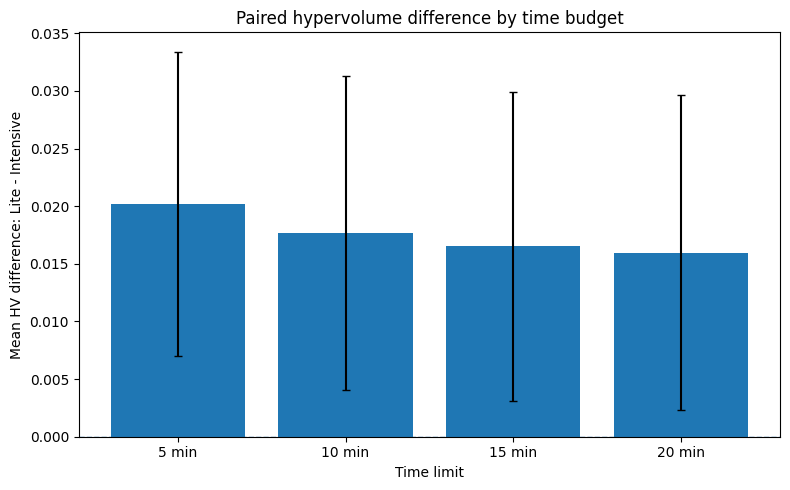

In [18]:
# Figure: Lite - Intensive difference by time limit.
plt.figure(figsize=(8, 5))

plot_df = paired_hv_summary.sort_values("time_limit_seconds")
plt.bar(
    plot_df["time_limit_label"],
    plot_df["mean_diff_lite_minus_intensive"],
    yerr=plot_df["ci95_diff"],
    capsize=3,
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Time limit")
plt.ylabel("Mean HV difference: Lite - Intensive")
plt.title("Paired hypervolume difference by time budget")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_fig_lite_minus_intensive_hv_by_time.png", dpi=300)
plt.show()

In [19]:
# Winners by instance and time limit, using mean HV over the 10 runs.
hv_instance_time = (
    hv_run
    .groupby(["time_limit_seconds", "time_limit_label", "instance_clean", "n_students", "algorithm_label"], observed=True)
    .agg(mean_hv=("hypervolume", "mean"), std_hv=("hypervolume", "std"), n_runs=("hypervolume", "count"))
    .reset_index()
)

hv_instance_time_pivot = hv_instance_time.pivot_table(
    index=["time_limit_seconds", "time_limit_label", "instance_clean", "n_students"],
    columns="algorithm_label",
    values="mean_hv",
    observed=True,
)[LABEL_ORDER].reset_index()

hv_instance_time_pivot["diff_lite_minus_intensive"] = hv_instance_time_pivot[LITE_LABEL] - hv_instance_time_pivot[INTENSIVE_LABEL]
hv_instance_time_pivot["winner"] = np.where(
    hv_instance_time_pivot["diff_lite_minus_intensive"] >= 0,
    LITE_LABEL,
    INTENSIVE_LABEL,
)

hv_instance_time_pivot = hv_instance_time_pivot.sort_values(["time_limit_seconds", "instance_clean"])
display(hv_instance_time_pivot)
hv_instance_time_pivot.to_csv(OUTPUT_DIR / "04_winners_by_instance_and_time.csv", index=False)

algorithm_label,time_limit_seconds,time_limit_label,instance_clean,n_students,HH-LAP-SIPA-Lite,HH-LAP-SIPA-Intensive,diff_lite_minus_intensive,winner
0,300,5 min,problem_instance_ext_1000_0,1000,0.062996,0.011632,0.051365,HH-LAP-SIPA-Lite
1,300,5 min,problem_instance_ext_1000_1,1000,0.001687,0.018615,-0.016928,HH-LAP-SIPA-Intensive
2,300,5 min,problem_instance_ext_1000_2,1000,0.081477,0.012053,0.069423,HH-LAP-SIPA-Lite
3,300,5 min,problem_instance_ext_1000_3,1000,0.008519,0.031481,-0.022962,HH-LAP-SIPA-Intensive
4,600,10 min,problem_instance_ext_1000_0,1000,0.063029,0.013394,0.049636,HH-LAP-SIPA-Lite
5,600,10 min,problem_instance_ext_1000_1,1000,0.001748,0.024111,-0.022363,HH-LAP-SIPA-Intensive
6,600,10 min,problem_instance_ext_1000_2,1000,0.081751,0.013137,0.068614,HH-LAP-SIPA-Lite
7,600,10 min,problem_instance_ext_1000_3,1000,0.008851,0.034032,-0.025181,HH-LAP-SIPA-Intensive
8,900,15 min,problem_instance_ext_1000_0,1000,0.063300,0.013933,0.049366,HH-LAP-SIPA-Lite
9,900,15 min,problem_instance_ext_1000_1,1000,0.001767,0.025906,-0.024139,HH-LAP-SIPA-Intensive


## 9. Improvement with time budget

This section checks whether each algorithm improves as the time limit increases.

In [20]:
# Paired improvement relative to 300 seconds for each algorithm, instance, and run.
hv_time_pivot = hv_run.pivot_table(
    index=["algorithm", "algorithm_label", "instance_clean", "n_students", "run_id"],
    columns="time_limit_seconds",
    values="hypervolume",
    observed=True,
)

# Keep only expected columns if present.
available_time_cols = [t for t in EXPECTED_TIME_LIMITS if t in hv_time_pivot.columns]
hv_time_pivot = hv_time_pivot[available_time_cols].reset_index()

base_time = 300
improvement_rows = []

for _, row in hv_time_pivot.iterrows():
    if base_time not in available_time_cols or pd.isna(row[base_time]):
        continue
    for t in available_time_cols:
        if t == base_time:
            continue
        improvement_rows.append({
            "algorithm": row["algorithm"],
            "algorithm_label": row["algorithm_label"],
            "instance_clean": row["instance_clean"],
            "n_students": row["n_students"],
            "run_id": row["run_id"],
            "from_time": base_time,
            "to_time": t,
            "from_label": TIME_LIMIT_LABELS.get(base_time, str(base_time)),
            "to_label": TIME_LIMIT_LABELS.get(t, str(t)),
            "hv_from": row[base_time],
            "hv_to": row[t],
            "hv_improvement": row[t] - row[base_time],
        })

hv_improvement = pd.DataFrame(improvement_rows)
display(hv_improvement.head())
hv_improvement.to_csv(OUTPUT_DIR / "05_hv_improvement_relative_to_300s_by_run.csv", index=False)

,algorithm,algorithm_label,instance_clean,n_students,run_id,from_time,to_time,from_label,to_label,hv_from,hv_to,hv_improvement
0,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,0,300,600,5 min,10 min,0.062995,0.063005,0.000009
1,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,0,300,900,5 min,15 min,0.062995,0.063300,0.000305
2,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,0,300,1200,5 min,20 min,0.062995,0.063343,0.000347
3,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1,300,600,5 min,10 min,0.062995,0.063005,0.000009
4,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1,300,900,5 min,15 min,0.062995,0.063300,0.000305


In [21]:
improvement_summary = (
    hv_improvement
    .groupby(["algorithm_label", "from_time", "to_time", "from_label", "to_label"], observed=True)
    .agg(
        n_pairs=("hv_improvement", "count"),
        mean_improvement=("hv_improvement", "mean"),
        std_improvement=("hv_improvement", "std"),
        median_improvement=("hv_improvement", "median"),
        ci95_improvement=("hv_improvement", ci95),
        positive_improvements=("hv_improvement", lambda x: (x > 0).sum()),
        non_positive_improvements=("hv_improvement", lambda x: (x <= 0).sum()),
    )
    .reset_index()
    .sort_values(["algorithm_label", "to_time"])
)

display(improvement_summary)
improvement_summary.to_csv(OUTPUT_DIR / "05_hv_improvement_relative_to_300s_summary.csv", index=False)

,algorithm_label,from_time,to_time,from_label,to_label,n_pairs,mean_improvement,std_improvement,median_improvement,ci95_improvement,positive_improvements,non_positive_improvements
0,HH-LAP-SIPA-Intensive,300,600,5 min,10 min,40,0.002723,0.001714,0.002170,0.000548,40,0
1,HH-LAP-SIPA-Intensive,300,900,5 min,15 min,40,0.004013,0.002017,0.003231,0.000645,40,0
2,HH-LAP-SIPA-Intensive,300,1200,5 min,20 min,40,0.004676,0.002849,0.003648,0.000911,40,0
3,HH-LAP-SIPA-Lite,300,600,5 min,10 min,40,0.000175,0.000227,0.000061,0.000072,32,8
4,HH-LAP-SIPA-Lite,300,900,5 min,15 min,40,0.000300,0.000256,0.000301,0.000082,32,8
5,HH-LAP-SIPA-Lite,300,1200,5 min,20 min,40,0.000419,0.000358,0.000344,0.000115,32,8


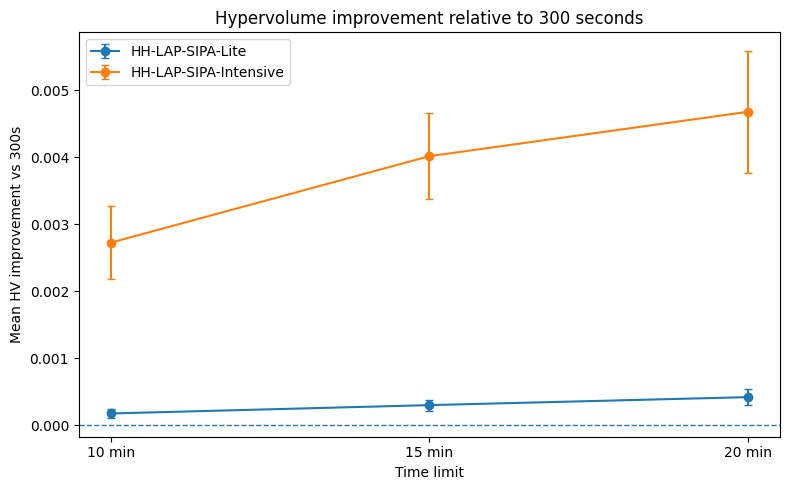

In [22]:
# Figure: improvement relative to 300 seconds.
plt.figure(figsize=(8, 5))

for label in LABEL_ORDER:
    sub = improvement_summary[improvement_summary["algorithm_label"] == label].sort_values("to_time")
    plt.errorbar(
        sub["to_time"],
        sub["mean_improvement"],
        yerr=sub["ci95_improvement"],
        marker="o",
        capsize=3,
        label=label,
    )

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Time limit")
plt.ylabel("Mean HV improvement vs 300s")
plt.title("Hypervolume improvement relative to 300 seconds")
plt.xticks([600, 900, 1200], [TIME_LIMIT_LABELS[t] for t in [600, 900, 1200]])
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_fig_hv_improvement_relative_to_300s.png", dpi=300)
plt.show()

## 10. Per-objective analysis

For each Pareto front, this section extracts the best value reached in each objective.

In [23]:
run_objective_summary = (
    pareto_all
    .groupby(["algorithm", "algorithm_label", "instance_clean", "n_students", "run_id", "time_limit_seconds", "time_limit_label"], observed=True)
    .agg(
        pareto_size=("source_file", "size"),
        best_tau_sum=("tau_sum", "max"),
        best_eta_sum=("eta_sum", "max"),
        best_lbar_sum=("lbar_sum", "min"),
        best_sigma_sum=("sigma_sum", "min"),
        best_tau_per_student=("tau_per_student", "max"),
        best_eta_per_student=("eta_per_student", "max"),
        mean_tau_sum=("tau_sum", "mean"),
        mean_eta_sum=("eta_sum", "mean"),
        mean_lbar_sum=("lbar_sum", "mean"),
        mean_sigma_sum=("sigma_sum", "mean"),
    )
    .reset_index()
    .sort_values(["time_limit_seconds", "algorithm", "instance_clean", "run_id"])
)

display(run_objective_summary.head())
run_objective_summary.to_csv(OUTPUT_DIR / "06_objectives_by_run.csv", index=False)

,algorithm,algorithm_label,instance_clean,n_students,run_id,time_limit_seconds,time_limit_label,pareto_size,best_tau_sum,best_eta_sum,best_lbar_sum,best_sigma_sum,best_tau_per_student,best_eta_per_student,mean_tau_sum,mean_eta_sum,mean_lbar_sum,mean_sigma_sum
0,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,0,300,5 min,14,787.774973,591.9052,1.608096,0.108571,0.787775,0.591905,589.122992,470.352900,1.617141,0.422524
4,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,1,300,5 min,14,787.774973,591.9052,1.608096,0.108571,0.787775,0.591905,589.122992,470.352900,1.617141,0.422524
8,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,2,300,5 min,12,787.774973,591.9052,1.609642,0.108571,0.787775,0.591905,590.116737,471.475250,1.618649,0.394286
12,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,3,300,5 min,13,787.774973,591.9052,1.609642,0.108571,0.787775,0.591905,605.276736,462.690546,1.618601,0.407289
16,hh_lap_v0,HH-LAP-SIPA-Lite,problem_instance_ext_1000_0,1000,4,300,5 min,13,787.774973,591.9052,1.609642,0.108571,0.787775,0.591905,605.276736,462.690546,1.618601,0.407289


In [24]:
objective_summary_by_time = (
    run_objective_summary
    .groupby(["time_limit_seconds", "time_limit_label", "algorithm", "algorithm_label"], observed=True)
    .agg(
        n_runs=("best_tau_sum", "count"),
        mean_best_tau_per_student=("best_tau_per_student", "mean"),
        std_best_tau_per_student=("best_tau_per_student", "std"),
        mean_best_eta_per_student=("best_eta_per_student", "mean"),
        std_best_eta_per_student=("best_eta_per_student", "std"),
        mean_best_lbar_sum=("best_lbar_sum", "mean"),
        std_best_lbar_sum=("best_lbar_sum", "std"),
        mean_best_sigma_sum=("best_sigma_sum", "mean"),
        std_best_sigma_sum=("best_sigma_sum", "std"),
        mean_pareto_size=("pareto_size", "mean"),
        std_pareto_size=("pareto_size", "std"),
    )
    .reset_index()
    .sort_values(["time_limit_seconds", "algorithm"])
)

display(objective_summary_by_time)
objective_summary_by_time.to_csv(OUTPUT_DIR / "06_objective_summary_by_time_algorithm.csv", index=False)

,time_limit_seconds,time_limit_label,algorithm,algorithm_label,n_runs,mean_best_tau_per_student,std_best_tau_per_student,mean_best_eta_per_student,std_best_eta_per_student,mean_best_lbar_sum,std_best_lbar_sum,mean_best_sigma_sum,std_best_sigma_sum,mean_pareto_size,std_pareto_size
0,300,5 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.793979,0.004471,0.590571,0.007297,1.219077,0.310734,0.208685,0.162529,12.750,5.873670
1,300,5 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.792894,0.004944,0.588645,0.007264,1.627419,0.502098,0.001080,0.000492,59.375,15.848137
2,600,10 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.794227,0.004607,0.590901,0.006753,1.217438,0.310557,0.208685,0.162529,15.775,6.573012
3,600,10 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.793576,0.004766,0.589655,0.008267,1.621154,0.509196,0.001072,0.000493,73.575,13.526588
4,900,15 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.794341,0.004531,0.591064,0.007003,1.215417,0.310252,0.208685,0.162529,18.350,9.037103
5,900,15 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.794201,0.004826,0.590534,0.008756,1.611782,0.503969,0.001072,0.000493,93.175,9.588689
6,1200,20 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,0.794341,0.004531,0.591064,0.007003,1.214124,0.311446,0.208685,0.162529,20.200,11.024914
7,1200,20 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,0.794726,0.004306,0.590705,0.008790,1.611782,0.503969,0.001068,0.000486,109.725,16.593152


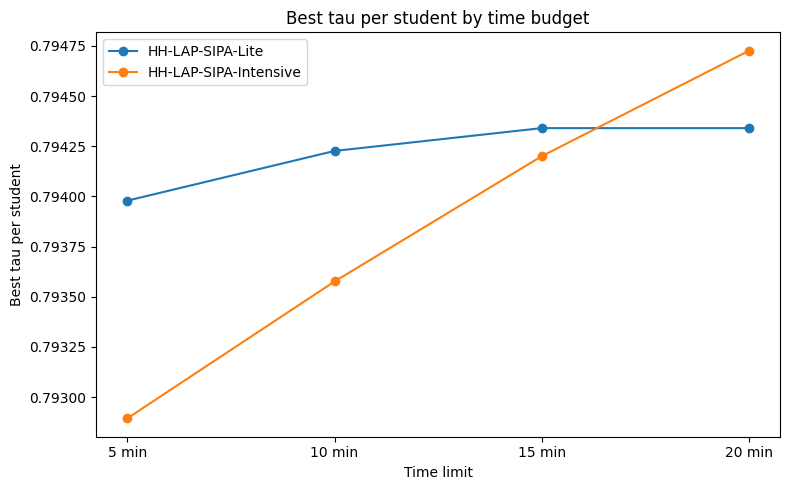

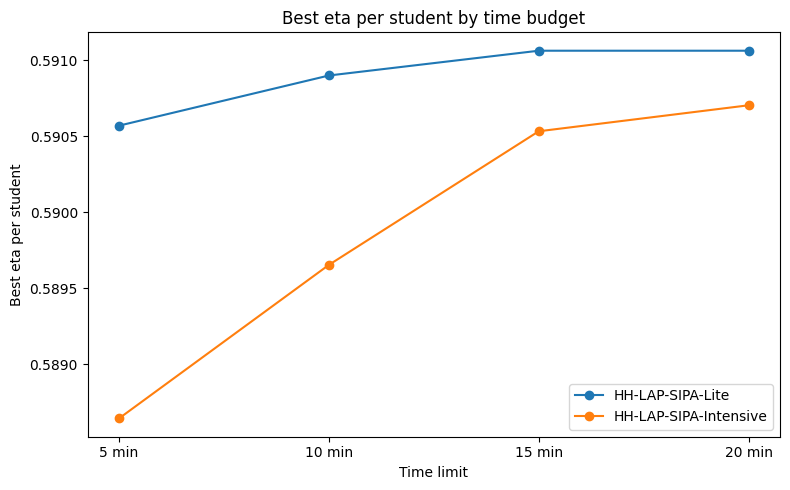

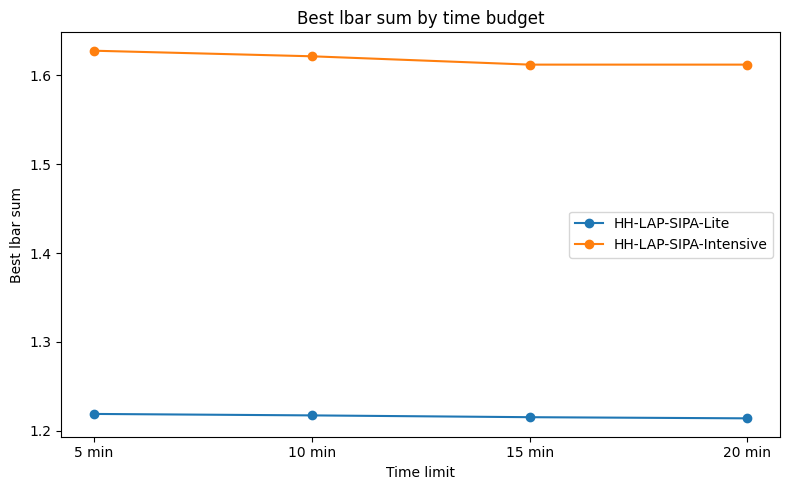

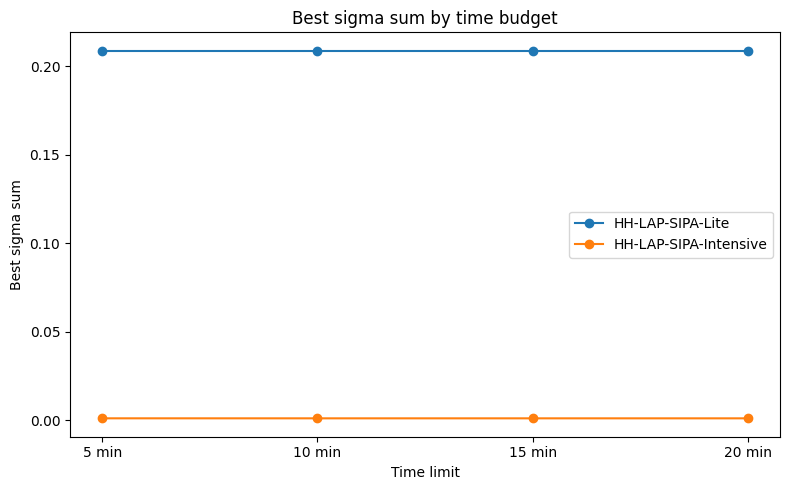

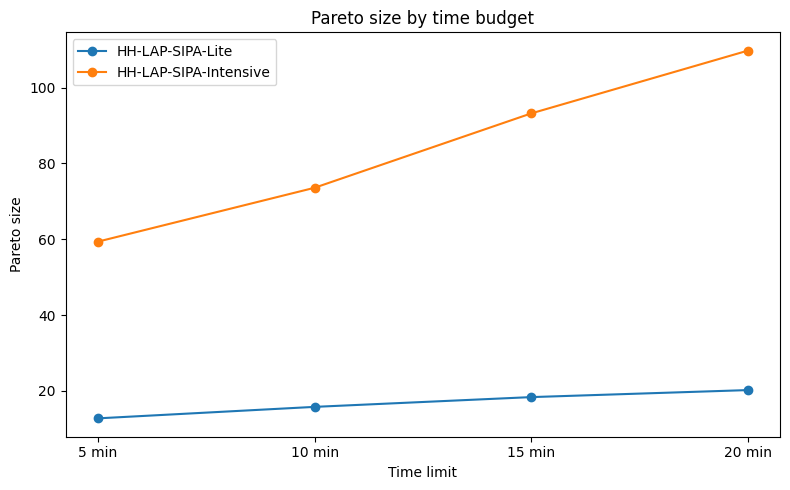

In [25]:
# Objective figures.
objective_plot_config = [
    ("mean_best_tau_per_student", "Best tau per student", "max"),
    ("mean_best_eta_per_student", "Best eta per student", "max"),
    ("mean_best_lbar_sum", "Best lbar sum", "min"),
    ("mean_best_sigma_sum", "Best sigma sum", "min"),
    ("mean_pareto_size", "Pareto size", "max"),
]

for col, ylabel, sense in objective_plot_config:
    plt.figure(figsize=(8, 5))
    for algorithm in ALGORITHM_ORDER:
        sub = objective_summary_by_time[objective_summary_by_time["algorithm"] == algorithm].sort_values("time_limit_seconds")
        plt.plot(
            sub["time_limit_seconds"],
            sub[col],
            marker="o",
            label=ALGORITHM_LABELS[algorithm],
        )

    plt.xlabel("Time limit")
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} by time budget")
    plt.xticks(EXPECTED_TIME_LIMITS, [TIME_LIMIT_LABELS[t] for t in EXPECTED_TIME_LIMITS])
    plt.legend()
    plt.tight_layout()
    safe_col = re.sub(r"[^a-zA-Z0-9_]+", "_", col)
    plt.savefig(OUTPUT_DIR / f"06_fig_{safe_col}_by_time.png", dpi=300)
    plt.show()

## 11. Runtime analysis

This section uses `statistics_all.csv` to check the observed elapsed time. It ignores budget columns when selecting the runtime column.

In [26]:
preferred_runtime_cols = [
    "elapsed_seconds",
    "runtime_seconds",
    "wall_time_seconds",
    "duration_seconds",
    "elapsed",
]

runtime_col = None

for col in preferred_runtime_cols:
    if col in stats_all.columns and pd.api.types.is_numeric_dtype(stats_all[col]):
        runtime_col = col
        break

if runtime_col is None:
    runtime_candidates = []
    for col in stats_all.columns:
        col_lower = col.lower()
        if "limit" in col_lower or "budget" in col_lower:
            continue
        if any(keyword in col_lower for keyword in ["runtime", "elapsed", "wall", "duration"]):
            if pd.api.types.is_numeric_dtype(stats_all[col]):
                runtime_candidates.append(col)
    if runtime_candidates:
        runtime_col = runtime_candidates[0]

print("Runtime column:", runtime_col)

if runtime_col is None:
    runtime_summary = pd.DataFrame()
    print("No runtime column found. Runtime analysis skipped.")
else:
    runtime_summary = (
        stats_all
        .groupby(["time_limit_seconds", "time_limit_label", "algorithm", "algorithm_label"], observed=True)
        .agg(
            n_runs=(runtime_col, "count"),
            mean_runtime=(runtime_col, "mean"),
            std_runtime=(runtime_col, "std"),
            median_runtime=(runtime_col, "median"),
            min_runtime=(runtime_col, "min"),
            max_runtime=(runtime_col, "max"),
            ci95_runtime=(runtime_col, ci95),
        )
        .reset_index()
        .sort_values(["time_limit_seconds", "algorithm"])
    )
    display(runtime_summary)
    runtime_summary.to_csv(OUTPUT_DIR / "07_runtime_summary_by_time_algorithm.csv", index=False)

Runtime column: elapsed_seconds


,time_limit_seconds,time_limit_label,algorithm,algorithm_label,n_runs,mean_runtime,std_runtime,median_runtime,min_runtime,max_runtime,ci95_runtime
0,300,5 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,304.521470,3.676850,303.597630,300.096910,313.669794,1.175914
1,300,5 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,303.108726,1.683567,303.046826,300.113641,306.553911,0.538431
2,600,10 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,607.034693,5.048783,605.826396,600.194809,619.107879,1.614679
3,600,10 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,603.307680,2.081990,603.649577,600.035323,607.614533,0.665853
4,900,15 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,906.466187,3.294586,906.425754,900.537200,917.316808,1.053660
5,900,15 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,902.993267,1.980588,902.706643,900.100194,907.742245,0.633423
6,1200,20 min,hh_lap_v0,HH-LAP-SIPA-Lite,40,1206.279171,4.620621,1204.707988,1200.710533,1218.633789,1.477746
7,1200,20 min,hh_lap_v1,HH-LAP-SIPA-Intensive,40,1202.976081,1.828367,1202.799232,1200.104332,1206.760401,0.584740


## 12. Final compact summary

This section creates a compact table intended to support the paper discussion.

In [28]:
final_summary = hv_by_time_algorithm[[
    "time_limit_seconds",
    "time_limit_label",
    "algorithm_label",
    "n_observations",
    "mean_hv",
    "std_hv",
    "median_hv",
    "ci95_hv",
    "mean_pareto_points",
]].copy()

# Add objective means.
objective_cols = [
    "time_limit_seconds",
    "algorithm_label",
    "mean_best_tau_per_student",
    "mean_best_eta_per_student",
    "mean_best_lbar_sum",
    "mean_best_sigma_sum",
    "mean_pareto_size",
]
final_summary = final_summary.merge(
    objective_summary_by_time[objective_cols],
    on=["time_limit_seconds", "algorithm_label"],
    how="left",
)

# Add runtime if available.
if runtime_col is not None and not runtime_summary.empty:
    final_summary = final_summary.merge(
        runtime_summary[["time_limit_seconds", "algorithm_label", "mean_runtime", "std_runtime", "median_runtime"]],
        on=["time_limit_seconds", "algorithm_label"],
        how="left",
    )

final_summary = final_summary.sort_values(["time_limit_seconds", "algorithm_label"])
display(final_summary)
final_summary.to_csv(OUTPUT_DIR / "08_final_compact_summary_by_time_algorithm.csv", index=False)

,time_limit_seconds,time_limit_label,algorithm_label,n_observations,mean_hv,std_hv,median_hv,ci95_hv,mean_pareto_points,mean_best_tau_per_student,mean_best_eta_per_student,mean_best_lbar_sum,mean_best_sigma_sum,mean_pareto_size,mean_runtime,std_runtime,median_runtime
1,300,5 min,HH-LAP-SIPA-Intensive,40,0.018445,0.008123,0.015247,0.002598,59.375,0.792894,0.588645,1.627419,0.001080,59.375,303.108726,1.683567,303.046826
0,300,5 min,HH-LAP-SIPA-Lite,40,0.038670,0.034720,0.035922,0.011104,12.750,0.793979,0.590571,1.219077,0.208685,12.750,304.521470,3.676850,303.597630
3,600,10 min,HH-LAP-SIPA-Intensive,40,0.021168,0.008758,0.018920,0.002801,73.575,0.793576,0.589655,1.621154,0.001072,73.575,603.307680,2.081990,603.649577
2,600,10 min,HH-LAP-SIPA-Lite,40,0.038845,0.034722,0.035987,0.011104,15.775,0.794227,0.590901,1.217438,0.208685,15.775,607.034693,5.048783,605.826396
5,900,15 min,HH-LAP-SIPA-Intensive,40,0.022459,0.008178,0.020773,0.002616,93.175,0.794201,0.590534,1.611782,0.001072,93.175,902.993267,1.980588,902.706643
4,900,15 min,HH-LAP-SIPA-Lite,40,0.038969,0.034727,0.036186,0.011106,18.350,0.794341,0.591064,1.215417,0.208685,18.350,906.466187,3.294586,906.425754
7,1200,20 min,HH-LAP-SIPA-Intensive,40,0.023121,0.008562,0.021793,0.002738,109.725,0.794726,0.590705,1.611782,0.001068,109.725,1202.976081,1.828367,1202.799232
6,1200,20 min,HH-LAP-SIPA-Lite,40,0.039088,0.034846,0.036223,0.011144,20.200,0.794341,0.591064,1.214124,0.208685,20.200,1206.279171,4.620621,1204.707988


In [29]:
# One-row key findings table.
best_rows = []
for time_limit, group in hv_by_time_algorithm.groupby("time_limit_seconds", observed=True):
    best = group.sort_values("mean_hv", ascending=False).iloc[0]
    paired = paired_hv_summary[paired_hv_summary["time_limit_seconds"] == time_limit]
    paired = paired.iloc[0] if len(paired) else None

    best_rows.append({
        "time_limit_seconds": time_limit,
        "time_limit_label": TIME_LIMIT_LABELS.get(int(time_limit), str(time_limit)),
        "best_algorithm_by_mean_hv": best["algorithm_label"],
        "best_mean_hv": best["mean_hv"],
        "mean_diff_lite_minus_intensive": paired["mean_diff_lite_minus_intensive"] if paired is not None else np.nan,
        "lite_wins_paired_runs": paired["lite_wins"] if paired is not None else np.nan,
        "intensive_wins_paired_runs": paired["intensive_wins"] if paired is not None else np.nan,
        "wilcoxon_p_value": paired["p_value"] if paired is not None and "p_value" in paired.index else np.nan,
    })

key_findings = pd.DataFrame(best_rows).sort_values("time_limit_seconds")
display(key_findings)
key_findings.to_csv(OUTPUT_DIR / "08_key_findings_by_time_budget.csv", index=False)

,time_limit_seconds,time_limit_label,best_algorithm_by_mean_hv,best_mean_hv,mean_diff_lite_minus_intensive,lite_wins_paired_runs,intensive_wins_paired_runs,wilcoxon_p_value
0,300,5 min,HH-LAP-SIPA-Lite,0.038670,0.020225,20,20,0.007156
1,600,10 min,HH-LAP-SIPA-Lite,0.038845,0.017676,20,20,0.007139
2,900,15 min,HH-LAP-SIPA-Lite,0.038969,0.016511,20,20,0.007118
3,1200,20 min,HH-LAP-SIPA-Lite,0.039088,0.015967,20,20,0.007123


## 13. Generated files

In [30]:
generated_files = sorted([p for p in OUTPUT_DIR.glob("**/*") if p.is_file()])

generated_files_df = pd.DataFrame({
    "file": [p.name for p in generated_files],
    "relative_path": [str(p.relative_to(OUTPUT_DIR)) for p in generated_files],
    "full_path": [str(p) for p in generated_files],
    "suffix": [p.suffix for p in generated_files],
})

display(generated_files_df)
generated_files_df.to_csv(OUTPUT_DIR / "09_generated_analysis_files.csv", index=False)

,file,relative_path,full_path,suffix
0,00_integrity_summary.csv,00_integrity_summary.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
1,01_all_pareto_solutions.csv,01_all_pareto_solutions.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
2,01_pareto_file_counts.csv,01_pareto_file_counts.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
3,01_pareto_file_metadata.csv,01_pareto_file_metadata.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
4,02_all_pareto_solutions_normalized.csv,02_all_pareto_solutions_normalized.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
5,02_hypervolume_by_run_recomputed.csv,02_hypervolume_by_run_recomputed.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
6,02_hypervolume_normalization_bounds.csv,02_hypervolume_normalization_bounds.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
7,02_hypervolume_summary_recomputed.csv,02_hypervolume_summary_recomputed.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
8,03_fig_hv_by_time_algorithm.png,03_fig_hv_by_time_algorithm.png,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.png
9,03_hv_by_time_algorithm.csv,03_hv_by_time_algorithm.csv,c:\Code\VRAIN-practicas\Code\Teachers+Centers\...,.csv
